# Спринт 3 - Проект модуля - нейросеть для классификации таблеток

--
В связи с недостуностью ВМ от Яндекс.Практикум, проект выполнен на собственном локальном компьютере без GPU

## Инициалиация

In [49]:
import random
import pandas as pd
import numpy as np
import pathlib as path
import torch
from dotenv import load_dotenv
import os
import matplotlib.pyplot as plt

load_dotenv()

SEED = 43
# пути

ds = os.getenv('OGYEIV2_DATASET_DEST_DIR', 'data/dataset/parsed') 
DATASET_PATH = path.Path(ds)
DATASET_PATH.mkdir(parents=True, exist_ok=True)

PREPROCESSING_PATH = path.Path('data/preprocessing')
PREPROCESSING_PATH.mkdir(parents=True, exist_ok=True)

MODELS_PATH = path.Path('data/models')
MODELS_PATH.mkdir(parents=True, exist_ok=True)

def init_random():
    """
    Инициализация случайных величин для повторяемости экспериментов
    """   
    torch.random.manual_seed(SEED)
    np.random.seed(SEED)
    random.seed(SEED)


## Этап 0 - подготовка
см. [readme.md](readme.md) для установки python и зависимостей

## Этап 1 - загрузка и подготовка данных

- Загрузить датасеты для обучения и валидации, определить операции предобработки, подготовить загрузчики `train_loader` и `val_loader`
- Вывести количество классов и изображений в каждом датасете

### Парсинга Kaggle датасета

** Важно: Загрузить архив по предоставленной ссылке на Яндекс Диск не получается (https://disk.yandex.ru/d/o4oQ4Yk7SpH1dw) - 500-ая ошибка.
Поэтому придется использовать оригинальный датасет с Kaggle - https://www.kaggle.com/datasets/richardradli/ogyeiv2/data
Датасет представлен в формате YOLO для задачи сегментации:
- изображение (jpg) в отдельной директории 
- метки класса в отдельной директории, с тем же именем файла (txt), что и изображение 
- файл с меткой содержит саму метку и набор координат (контур полигона), в котором находится объект на изображении.

Для задачи классификации необходимо сначала предобработать датасет для получения классической структуры:
- директория соответсвует названию класса
- внутри директории находятся изображения этого класса, вырезанные из исходно изображения, согласно представленным координатам

#### Посмотрим как выглядит выборочная (1-ая) картинка и каким контуром (сегментом) она задана

In [51]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

def parse_and_crop_image(img: Image.Image, label_segment: str, margin = 100):   
    """
    Распарсивает контур объекта на изображении:
    - формирует обрезанное изображение только заданного объекта без лишней информации с исходного изображения
    - добавляет отступ (margin) от края изображения, чтобы захватить немного фона вокруг

    Returns:
        image_crop: Image - обрезанное изображение
        (points_x, points_y): tuple(float[], floatp[]) - точки (координат) контура
        (left, top, right, down): tuple(int, int, int, int) - границы (координаты) рамки вырезания объекта
    """
    
    # parse segment points
    coords = label_segment.split()[1:]
    points_x = [float(x) for x in coords[0::2]]
    points_y = [float(y) for y in coords[1::2]]

    # scale back to original sizes
    W, H = img.width, img.height
    points_x = np.array(points_x) * W
    points_y = np.array(points_y) * H

    # bounding box
    x_min, x_max = min(points_x), max(points_x)
    y_min, y_max = min(points_y), max(points_y)

    # add external margins for visual comfort
    margin = 100    
    left = max(0, x_min - margin)
    right = min(W, x_max + margin)
    top = max(0, y_min - margin)
    down = min(H, y_max + margin)
    image_crop = img.crop(box=(left, top, right, down))

    return image_crop, (points_x, points_y), (left, top, right, down)

def plot_image_from_dataset(img: Image.Image, name:str, label_segment:str, margin = 100):
    """
    Выводит картинку оригинального, а также обрезанное изображение, согласно информации о сегментации картинки
    """
    # parse class label
    label = label_segment.split()[0]
    image_crop, (points_x, points_y), (left, top, right, down) = parse_and_crop_image(img, label_segment, margin)
    
    # prepare plot
    plt.figure(figsize=(10,4))

    # original image
    plt.subplot(1,2,1)
    plt.imshow(img)
    
    # segment contour by points
    plt.plot(points_x, points_y)
    plt.title(f'label = {label} | image = {name}.jpg')

    # plot box
    plt.vlines([left, right], ymin=down, ymax=top, color='green')
    plt.hlines([top, down], xmin=left, xmax=right, color='green')

    x_min, x_max = min(points_x), max(points_x)
    y_min, y_max = min(points_y), max(points_y)
    plt.scatter([x_min, x_max],[y_min, y_max], marker='x')

    plt.legend(['segment (+corners)', f'borders with margins ({margin})'])
    
    # plot cropped image
    plt.subplot(1,2,2)
    
    plt.imshow(image_crop)
    t = plt.title('Cropped image')

    ### info
    print(f'label: = {label}')
    print(f'borders: (x_min, y_min) = ({x_min:.0f}, {y_min:.0f}), (x_max, y_max) = ({x_max:.0f}, {y_max:.0f})')

label: = 0
borders: (x_min, y_min) = (505, 1251), (x_max, y_max) = (988, 1734)


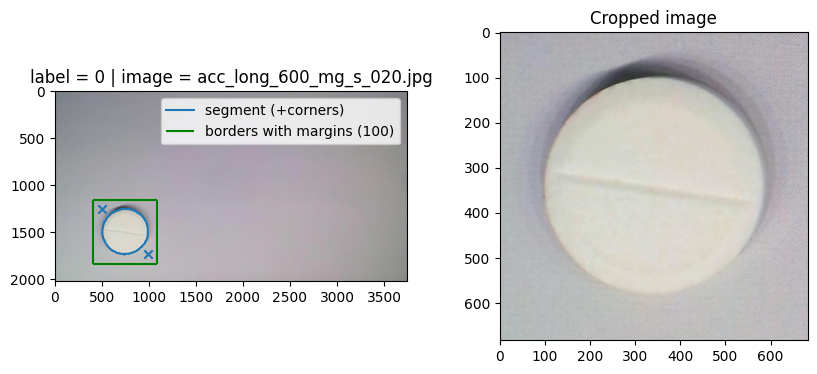

In [ ]:
# возьмем образец изображения и его описания
# - фото        - acc_long_600_mg_s_020.jpg
# - описание    - acc_long_600_mg_s_020.txt

from PIL import Image
import matplotlib.pyplot as plt
import pathlib as path


# read image
data_path = path.Path('data/dataset/sample')
image_name = 'acc_long_600_mg_s_020'
image_path = data_path / (image_name + '.jpg')
image = Image.open(image_path)

# read label and segment points
with open(data_path / (image_name + '.txt')) as f:
    label_segment = f.readline()

# plot image
plot_image_from_dataset(image, image_name, label_segment, margin=100)


 #### Подготовим датасет с обрезанными изображениями в формате задачи классификации
 Целевой формат датасет - для каждого класса своя директория, внутри которой находятся соответсвующие изображения.

```bash
uv add dotenv 
```

In [47]:
from pathlib import Path
from PIL import Image
from tqdm import tqdm

def preprocess_dataset(src_dir, dst_dir):
    """
    Конвертация исходного Kaggle OGYEIv2 датасета к формату директорий для задачи классификации, 
    где директория соответсвует классу изображений, которые в ней находятся.
    
    При этом изображения обрезаются согласно заданному контуру в датасете, чтобы убрать выделить именно целевой объект и удалить лишний фон (или что еще лишнее могло попасть на изображение)
    """
    
    print(f'preprocess_dataset() src_dir = {src_dir}, dst_dir = {dst_dir}')

    ds_types = ['train', 'valid', 'test']
    for ds_type in ds_types:
        print(f"Processing {ds_type} split...")
        
        images_path = src_dir / ds_type / "images"
        labels_path = src_dir / ds_type / "labels"
        
        # Ensure the destination directory for this split exists
        split_dst = dst_dir / ds_type
                
        # Iterate through all label files
        for label_file in tqdm(labels_path.glob("*.txt"), ds_type):

            # Find corresponding image file
            # Try common extensions: .jpg, .jpeg, .png
            img_stem = label_file.stem
            img_file = images_path / f"{img_stem}.jpg"
                            
            if img_file is None:
                print(f"Warning: Image for {label_file.name} not found. Skipping.")
                continue

            # Open the image
            img = Image.open(img_file)
            
            # Read the label file
            with open(label_file, 'r') as f:
                line = f.readline()

            if not line:
                continue
            
            # YOLO format: <class_id> <x1> <y1> <x2> <y2> ...
            parts = line.split()
            class_id = parts[0]
            
            try:
                # Use the provided function to crop
                # We pass the whole line as label_segment
                image_crop, _, _ = parse_and_crop_image(img, line)
                
                # Create class directory: dst_dir/train/0/

                # Важно: use zfill(3) to force folder names to be lexicographically sorted - used by torchvisiion dataset ImageFolder
                class_dir = split_dst / class_id.zfill(3)

                class_dir.mkdir(parents=True, exist_ok=True)

                # Save the cropped image
                # Filename: original_name_object_index.jpg
                save_path = class_dir / img_file.name
                
                image_crop.convert("RGB").save(save_path, "JPEG")
                
            except Exception as e:
                print(f"Error processing {label_file.name}: {e}")

    print("Preprocessing complete!")

In [53]:
from dotenv import load_dotenv
import os

load_dotenv()

src = os.getenv('OGYEIV2_DATASET_SRC_DIR')  # d:/AI_tools/Kaggle/datasets/richardradli/ogyeiv2/ogyeiv2/ogyeiv2
dst_dir = Path(DATASET_PATH)

# если директория еще не заполнена, то запускаем преобразование
if not any(dst_dir.iterdir()):
    if src is None:
        print('Env variable is not set (check .env) - OGYEIV2_DATASET_SRC_DIR')
    else:
        src_dir = Path(src)

    preprocess_dataset(src_dir, dst_dir)

preprocess_dataset() src_dir = d:\AI_tools\Kaggle\datasets\richardradli\ogyeiv2\ogyeiv2\ogyeiv2, dst_dir = data\dataset\ogyeiv2\parsed
Processing train split...


train: 3136it [02:47, 18.69it/s]


Processing valid split...


valid: 672it [00:36, 18.62it/s]


Processing test split...


test: 672it [00:34, 19.28it/s]

Preprocessing complete!


### Подготовка и трансформация датасета

Теперь обрезанные изображения подготовлены в директории проекта `data\dataset\ogyeiv2\parsed` и разделены на выборки для обучения, валидации и тренировки 

- готовим трансформации изображений и загрузчик для подачи данных в модель
    - аугментацию (повороты, отражения) применять не нужно, так как исходные изображения и так представлены в разных ракурсах и положениях
    - выполним стандартные трансформации для подготовки изображений действия:
        - приведение к единому размеру (Resize) - 224 x 224 (это стандарт для модели ResNet-50)
        - масштабирование (приведение к диапазону [0,1])
        - нормализация
            - стандарт ImageNet: mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]

```bash
uv add "torchvision==0.22.0+cpu"
```

In [89]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision.datasets import ImageFolder
from torchvision.transforms.v2 import Compose, Resize, CenterCrop, ToImage, ToDtype, Normalize

# трансформации
imagenet_mean = torch.tensor([0.485, 0.456, 0.406])
imagenet_std = torch.tensor([0.229, 0.224, 0.225])
transforms = Compose([
    Resize(size=256), # делаем чуть больший размер по меньшей стороне, чтобы гарантированно вырезать центр 224x224 без искажений
    CenterCrop(size=224),
    Resize(size=224), # так как отступы уже заданы при подготовке, доболнительно обрезать по центру не нужно
    ToImage(),
    ToDtype(dtype=torch.float32, scale=True),
    Normalize(mean=list(imagenet_mean.numpy()), std=list(imagenet_std.numpy()))
])

# датасеты
dst_dir = DATASET_PATH
train_dataset = ImageFolder(dst_dir / "train", transform=transforms)
val_dataset = ImageFolder(dst_dir / "valid", transform=transforms)
test_dataset = ImageFolder(dst_dir / "test", transform=transforms)

print(f'train_dataset = {len(train_dataset)}, val_dataset = {len(val_dataset)}, test_dataset = {len(test_dataset)}')

train_dataset = 3136, val_dataset = 672, test_dataset = 672


#### Помотрим распределение изображений по классам

In [70]:
# Помотрим распределение изображений по классам

import pandas as pd

# соберем данные в pandas DataFrame и посмотрим распределение
stats_df = pd.DataFrame(train_dataset.samples, columns=['name', 'label'])
stats_df['name'] = stats_df['name'].apply(lambda name: name.split("\\")[-1])

print(f'Всего классов: {stats_df["label"].nunique()}\n')

# посмотрим распределение
label_distrib = stats_df.groupby(by='label').count().rename(columns={'name': 'count'})
print(f'Распределение таблеток по классам: \n {label_distrib.describe()}\n')

Всего классов: 111

Распределение таблеток по классам: 
             count
count  111.000000
mean    28.252252
std      2.657642
min     28.000000
25%     28.000000
50%     28.000000
75%     28.000000
max     56.000000



Результат:
- 111 классов (должно быть 112!) - один потерян
- 28 примеров на класс
- выброс на 56 примеров элементов

In [74]:
# посмотрим на выбросы, у кого больше 28 изображений на класс
label_distrib[label_distrib['count'] > 28]

,count
label,
5,56


In [75]:
# видим, что в 5-м классе (метке) присутсвуют разные таблетки 
bad_cls = stats_df[stats_df['label'] == 5]
print(bad_cls.head(), '\n', bad_cls.tail())

                           name  label
140  algopyrin_500_mg_s_001.jpg      5
141  algopyrin_500_mg_s_003.jpg      5
142  algopyrin_500_mg_s_004.jpg      5
143  algopyrin_500_mg_s_005.jpg      5
144  algopyrin_500_mg_s_006.jpg      5 
                   name  label
191  cold_fx_u_015.jpg      5
192  cold_fx_u_016.jpg      5
193  cold_fx_u_017.jpg      5
194  cold_fx_u_018.jpg      5
195  cold_fx_u_019.jpg      5


Вывод по распределению по классам:
- train датасет - 28 примеров на каждый класс
- val датасет - 6 примеров на каждый класс
- test датасет - 6 примеров на каждый класс

При этом в каждом датасете есть ошибка в классе "5" - там содержаться два разных вида таблеток, например:
- algopyrin_500_mg_s_006.jpg
- cold_fx_u_015.jpg

При этом 1 класс потерян, и можно понять, что 21-ый класс, должен содержать "cold_fx", но его нет, так как его метка определена как 5-ый класс - что является ошибка в самом оригинальном датасете.

#### Исправление ошибки присвоения метки класса для "cold_fx" (было 5, должно быть 21)

In [ ]:
# Для исправления этой ситуации, перенесем перенесем все изображения с именем "cold_fx" в свой правильный класс "021"

%%cmd

# train
mkdir "data/dataset/ogyeiv2/parsed/train/021"
mv "data/dataset/ogyeiv2/parsed/train/005/cold_fx*.jpg" "data/dataset/ogyeiv2/parsed/train/021"

# valid
mkdir "data/dataset/ogyeiv2/parsed/valid/021"
mv "data/dataset/ogyeiv2/parsed/valid/005/cold_fx*.jpg" "data/dataset/ogyeiv2/parsed/valid/021"

# test
mkdir "data/dataset/ogyeiv2/parsed/test/021"
mv "data/dataset/ogyeiv2/parsed/test/005/cold_fx*.jpg" "data/dataset/ogyeiv2/parsed/test/021"


#### Пересобираем датасеты

In [91]:
# датасеты
dst_dir = DATASET_PATH
train_dataset = ImageFolder(dst_dir / "train", transform=transforms)
val_dataset = ImageFolder(dst_dir / "valid", transform=transforms)
test_dataset = ImageFolder(dst_dir / "test", transform=transforms)

print(f'train_dataset = {len(train_dataset)}, val_dataset = {len(val_dataset)}, test_dataset = {len(test_dataset)}')

# загрузчики
init_random()
batch_size = 32
train_loaded = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)
val_loaded = DataLoader(dataset=val_dataset, batch_size=batch_size)
test_loaded = DataLoader(dataset=test_dataset, batch_size=batch_size)

train_dataset = 3136, val_dataset = 672, test_dataset = 672


In [78]:
# Проверяем, что распределение теперь не содержит выбросов

import pandas as pd

for ds_name, ds in {'train': train_dataset, 'val': val_dataset, 'test': test_dataset}.items():
    # соберем данные в pandas DataFrame и посмотрим распределение
    stats_df = pd.DataFrame(ds.samples, columns=['name', 'label'])
    stats_df['name'] = stats_df['name'].apply(lambda name: name.split("\\")[-1])

    print(f'{ds_name}: Всего классов: {stats_df["label"].nunique()}\n')

    # посмотрим распределение
    label_distrib = stats_df.groupby(by='label').count().rename(columns={'name': 'count'})
    print(f'{ds_name}: Распределение таблеток по классам: \n {label_distrib.describe()}\n')

train: Всего классов: 112

train: Распределение таблеток по классам: 
        count
count  112.0
mean    28.0
std      0.0
min     28.0
25%     28.0
50%     28.0
75%     28.0
max     28.0

val: Всего классов: 112

val: Распределение таблеток по классам: 
        count
count  112.0
mean     6.0
std      0.0
min      6.0
25%      6.0
50%      6.0
75%      6.0
max      6.0

test: Всего классов: 112

test: Распределение таблеток по классам: 
        count
count  112.0
mean     6.0
std      0.0
min      6.0
25%      6.0
50%      6.0
75%      6.0
max      6.0



Теперь ошибка исправлена по всем сплитам датасета:
- количестово классов 112
- распределение объектов по классам равномерное - 28 / 6 / 6

### Проверка, что данные читаются и корректно трансформируются

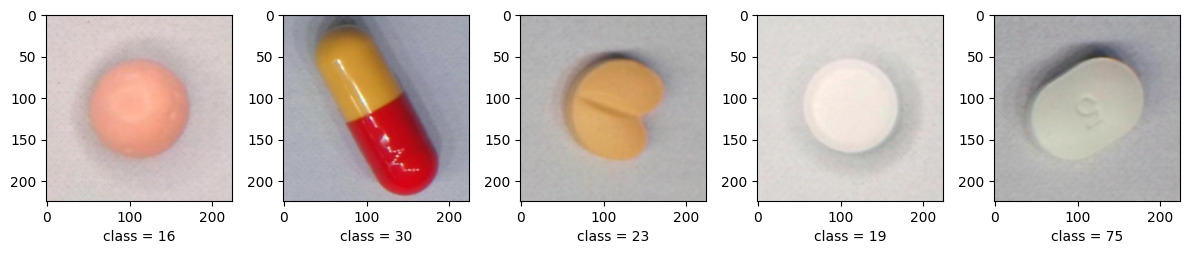

In [93]:
# пример данных
init_random()
sample_batch = next(iter(train_loaded))
sample_batch_images= sample_batch[0]
sample_batch_labels = sample_batch[1]

plt.figure(figsize=(12,3))
for i in range(5):
    img = sample_batch_images[i]
    class_label = sample_batch_labels[i].item()

    # денормализация для возврата в диапазон [0,1]
    img = img * imagenet_std.view(3,1,1) + imagenet_mean.view(3,1,1)

    plt.subplot(1,5,i+1)
    plt.imshow(img.permute(1,2,0)); plt.xlabel(f'class = {class_label}')

plt.tight_layout()

### Результат этапа
- данные загружены с сайта Kaggle, так как Яндекс Диск не доступен, данные представлены в формате YOLO для сегментации
- выполнено преобразование Kaggle-датасета в формат задачи классификации:
    - фотографии обрезаны согласно заданному контуру - это сильно снизило размер изображения и оставило на фото только саму таблетку, без лишнего фона и всего остального что могло быть на оригинальном фото
    - изображения перенесены в стандартную структуру директорий - название соответствует классу изображений, которые в ней содержатся
- обнаружена ошибка в исходном датасете по распределению изображений по классам:
    - таблетки "cold_fx" имели ошибочную метку "5", и находились вместе с правильными таблетками "algopyrin"
    - по этой причине, также был пропущен класс "21" для "cold_fx" - что показывало количество классов 111, а должно быть 112 согласно описанию датасета и представленным классам
- ошибка исправлена, теперь распределение корректное
    - количество классов 112
    - распределение объектов по классам равномерное - 28 / 6 / 6

## Этап 2 - Объявление модели
- Создать классификатор, подходящий для задачи, если часть весов нужно заморозить, сделайте это

Попробуем использовать стандартную предобученную модель ResNet-50 и заменим последний слой классификатора, для выдачи результата на 112 классов

```bash
uv add torchsummary
```

In [101]:
from torchvision.models import resnet50, ResNet50_Weights
from torchsummary import summary

model = resnet50(weights=ResNet50_Weights.IMAGENET1K_V1)

print(f'Original last linear layer = {model.fc}')
summary(model, input_size=(3,224,224))

Original last linear layer = Linear(in_features=2048, out_features=1000, bias=True)
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 64, 112, 112]           9,408
       BatchNorm2d-2         [-1, 64, 112, 112]             128
              ReLU-3         [-1, 64, 112, 112]               0
         MaxPool2d-4           [-1, 64, 56, 56]               0
            Conv2d-5           [-1, 64, 56, 56]           4,096
       BatchNorm2d-6           [-1, 64, 56, 56]             128
              ReLU-7           [-1, 64, 56, 56]               0
            Conv2d-8           [-1, 64, 56, 56]          36,864
       BatchNorm2d-9           [-1, 64, 56, 56]             128
             ReLU-10           [-1, 64, 56, 56]               0
           Conv2d-11          [-1, 256, 56, 56]          16,384
      BatchNorm2d-12          [-1, 256, 56, 56]             512
           Conv2d-1

Данные исходной модели ResNet-50:
- количество обучаемых параметров: 25,557,032

>```
>... <skip conv layers>
>          Linear-174                 [-1, 1000]       2,049,000
>================================================================
>Total params: 25,557,032
>Trainable params: 25,557,032
>Non-trainable params: 0
>----------------------------------------------------------------
>Input size (MB): 0.57
>Forward/backward pass size (MB): 286.56
>Params size (MB): 97.49
>Estimated Total Size (MB): 384.62
>----------------------------------------------------------------
>```

In [ ]:
# Заменяем последний линейный слой `fc` и замораживаем все веса кроме этого слоя

import torch.nn as nn

# меняем выходной слой
model.fc = nn.Linear(in_features=2048, out_features=112)

# замораживаем веса
for p in model.parameters():
    p.requires_grad = False

# размораживаем веса последнего слоя
for p in model.fc.parameters():
    p.requires_grad = True

print(f'Modified last linear layer = {model.fc}')

summary(model, input_size=(3,224,224))

Modified last linear layer = Linear(in_features=2048, out_features=112, bias=True)
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 64, 112, 112]           9,408
       BatchNorm2d-2         [-1, 64, 112, 112]             128
              ReLU-3         [-1, 64, 112, 112]               0
         MaxPool2d-4           [-1, 64, 56, 56]               0
            Conv2d-5           [-1, 64, 56, 56]           4,096
       BatchNorm2d-6           [-1, 64, 56, 56]             128
              ReLU-7           [-1, 64, 56, 56]               0
            Conv2d-8           [-1, 64, 56, 56]          36,864
       BatchNorm2d-9           [-1, 64, 56, 56]             128
             ReLU-10           [-1, 64, 56, 56]               0
           Conv2d-11          [-1, 256, 56, 56]          16,384
      BatchNorm2d-12          [-1, 256, 56, 56]             512
           Conv2d-13

Данные модели ResNet-50 подготовленной для обучения на задачую классификации на 112 классов:
- количество обучаемых параметров = 229,488

>```
>... <skip conv layers>
>          Linear-174                  [-1, 112]         229,488
>================================================================
>Total params: 23,737,520
>Trainable params: 229,488
>Non-trainable params: 23,508,032
>----------------------------------------------------------------
>Input size (MB): 0.57
>Forward/backward pass size (MB): 286.55
>Params size (MB): 90.55
>Estimated Total Size (MB): 377.68
>----------------------------------------------------------------
>```

### Результат этапа
Выполнено:
- создан классификатор ResNet-50 с предобученными весами IMAGENET1K_V1
- заменен последний линейный слой для 112 классов
- заморожены веса, кроме последнего слоя
- количество обучаемых параметров = 229,488